<a href="https://colab.research.google.com/github/rpa0855-ai/customer-segmentation-similarity-search/blob/main/Customer_Segmentation_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 0: Install/Import Libraries

In [ ]:
# first, install any missing library (safe to run even if already installed)
import sys
!{sys.executable} -m pip install -q openpyxl pandas numpy scikit-learn matplotlib seaborn
impot
# now import everything we need
import pandas as pd      # for tables (like Excel)
import numpy as np       # for numbers and math
import matplotlib.pyplot as plt   # for charts
import seaborn as sns             # for nicer charts

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, silhouette_samples
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# make charts look nice and show inside the notebook
sns.set_theme(style="whitegrid")
%matplotlib inline

print("Done! All libraries are ready.")

Done! All libraries are ready.


## Step 1: Load the Data
Change `file_path` below to where YOUR `online_retail_II.xlsx` file is saved.

In [ ]:
import os

# type your file location here
file_path = "C:/Users/rpa08/Downloads/online_retail_II.xlsx"

# the excel file has 2 sheets (2 tabs) - read them one at a time
sheet_1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
sheet_2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

# stick both sheets together into one big table
tx = pd.concat([sheet_1, sheet_2], ignore_index=True)

# rename a column (it had a space in the name, which is annoying to type)
tx = tx.rename(columns={"Customer ID": "CustomerID"})

print("Number of rows and columns:", tx.shape)
print("Number of unique customers:", tx["CustomerID"].nunique())

tx.head()   # show the first 5 rows

Number of rows and columns: (1067371, 8)
Number of unique customers: 5942


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Step 2: Data Preprocessing & Real RFM Feature Engineering
- Drops line items with no CustomerID, cancelled invoices, bad rows, duplicates
- Engineers **real** Recency, Frequency, Monetary (TotalSpending), Average Order Value, and Distinct-Product count directly from the transaction log
- Adds an IsUK flag, caps outliers (IQR), and standardizes features

In [ ]:
# we are going to clean the data step by step
# each step removes some "bad" rows

print("Rows before cleaning:", len(tx))

# step 1: remove rows where we don't know the customer
tx = tx.dropna(subset=["CustomerID"])
print("Rows after removing missing CustomerID:", len(tx))

# step 2: remove cancelled orders (Invoice number starts with letter C)
tx["Invoice"] = tx["Invoice"].astype(str)
tx = tx[tx["Invoice"].str.startswith("C") == False]
print("Rows after removing cancelled orders:", len(tx))

# step 3: remove rows with bad numbers (quantity or price should be positive)
tx = tx[tx["Quantity"] > 0]
tx = tx[tx["Price"] > 0]
print("Rows after removing bad quantity/price:", len(tx))

# step 4: remove duplicate rows (same row appearing twice by mistake)
tx = tx.drop_duplicates()
print("Rows after removing duplicates:", len(tx))

# now let's add a new column: how much money did this one line item cost
tx["LineTotal"] = tx["Quantity"] * tx["Price"]

# make sure CustomerID is a whole number, not a decimal
tx["CustomerID"] = tx["CustomerID"].astype(int)

print("")
print("Cleaning is done")
print("Final rows:", len(tx))
print("Final unique customers:", tx["CustomerID"].nunique())

Rows before cleaning: 779425
Rows after removing missing CustomerID: 779425
Rows after removing cancelled orders: 779425
Rows after removing bad quantity/price: 779425
Rows after removing duplicates: 779425

Cleaning is done
Final rows: 779425
Final unique customers: 5878


In [ ]:
# now we turn "many rows per customer" into "one row per customer"
# we will calculate: Recency, Frequency, Total Spending, Products bought

# snapshot_date = one day after the last purchase in our data
# (we use this instead of today's date, because this data is old)
last_date = tx["InvoiceDate"].max()
snapshot_date = last_date + pd.Timedelta(days=1)

# group all rows by customer, and calculate numbers for each customer
customer = tx.groupby("CustomerID").agg(
    Recency = ("InvoiceDate", lambda dates: (snapshot_date - dates.max()).days),
    Frequency = ("Invoice", "nunique"),
    TotalSpending = ("LineTotal", "sum"),
    NumDistinctProducts = ("StockCode", "nunique"),
)
customer = customer.reset_index()

# average order size = total spent divided by number of orders
customer["AvgOrderValue"] = customer["TotalSpending"] / customer["Frequency"]
customer["AvgOrderValue"] = customer["AvgOrderValue"].round(2)
customer["TotalSpending"] = customer["TotalSpending"].round(2)

# find the most common country for each customer
country_per_customer = tx.groupby("CustomerID")["Country"].agg(lambda x: x.mode().iloc[0])
customer["Country"] = customer["CustomerID"].map(country_per_customer)
customer["IsUK"] = (customer["Country"] == "United Kingdom").astype(int)

print("Customer table created")
print("Number of customers:", len(customer))
customer.head()

Customer table created
Number of customers: 5878


,CustomerID,Recency,Frequency,TotalSpending,NumDistinctProducts,AvgOrderValue,Country,IsUK
0,12346,326,12,77556.46,27,6463.04,United Kingdom,1
1,12347,2,8,4921.53,126,615.19,Iceland,0
2,12348,75,5,2019.40,25,403.88,Finland,0
3,12349,19,4,4428.69,138,1107.17,Italy,0
4,12350,310,1,334.40,17,334.40,Norway,0


In [ ]:
# some customers have EXTREME numbers (like one giant order).
# instead of deleting them, we "cap" them - push them back to a normal range.

def cap_extreme_values(column):
    q1 = column.quantile(0.25)   # 25th percentile
    q3 = column.quantile(0.75)   # 75th percentile
    spread = q3 - q1
    lower_limit = q1 - 1.5 * spread
    upper_limit = q3 + 1.5 * spread
    how_many_extreme = ((column < lower_limit) | (column > upper_limit)).sum()
    fixed_column = column.clip(lower_limit, upper_limit)
    return fixed_column, how_many_extreme

feature_cols = ["Recency", "Frequency", "TotalSpending", "AvgOrderValue", "NumDistinctProducts", "IsUK"]

for col_name in feature_cols[:-1]:   # don't touch IsUK, it's already just 0 or 1
    customer[col_name], count_fixed = cap_extreme_values(customer[col_name])
    print("Fixed", count_fixed, "extreme values in", col_name)

# now scale all numbers so they use the same "unit" - fair comparison
scaler = StandardScaler()
scaled_values = scaler.fit_transform(customer[feature_cols])

# put the scaled numbers into a new table, with "_z" added to each column name
scaled_column_names = [name + "_z" for name in feature_cols]
X_scaled = pd.DataFrame(scaled_values, columns=scaled_column_names)

# combine the original customer table with the new scaled numbers
df = pd.concat([customer.reset_index(drop=True), X_scaled], axis=1)

print("")
print("Scaling done Final table shape:", df.shape)
df.head()

Fixed 0 extreme values in Recency
Fixed 0 extreme values in Frequency
Fixed 0 extreme values in TotalSpending
Fixed 0 extreme values in AvgOrderValue
Fixed 0 extreme values in NumDistinctProducts

Scaling done Final table shape: (5878, 14)


,CustomerID,Recency,Frequency,TotalSpending,NumDistinctProducts,AvgOrderValue,Country,IsUK,Recency_z,Frequency_z,TotalSpending_z,AvgOrderValue_z,NumDistinctProducts_z,IsUK_z
0,12346,326,12,5107.3425,27,772.22625,United Kingdom,1,0.595584,1.535993,2.156176,2.347975,-0.638155,0.314152
1,12347,2,8,4921.5300,126,615.19000,Iceland,0,-0.952279,0.670587,2.042726,1.530386,0.807897,-3.183171
2,12348,75,5,2019.4000,25,403.88000,Finland,0,-0.603532,0.021532,0.270798,0.430227,-0.667368,-3.183171
3,12349,19,4,4428.6900,138,772.22625,Italy,0,-0.871064,-0.194820,1.741817,2.347975,0.983176,-3.183171
4,12350,310,1,334.4000,17,334.40000,Norway,0,0.519146,-0.843874,-0.757997,0.068488,-0.784221,-3.183171


## Step 3: Exploratory Data Analysis

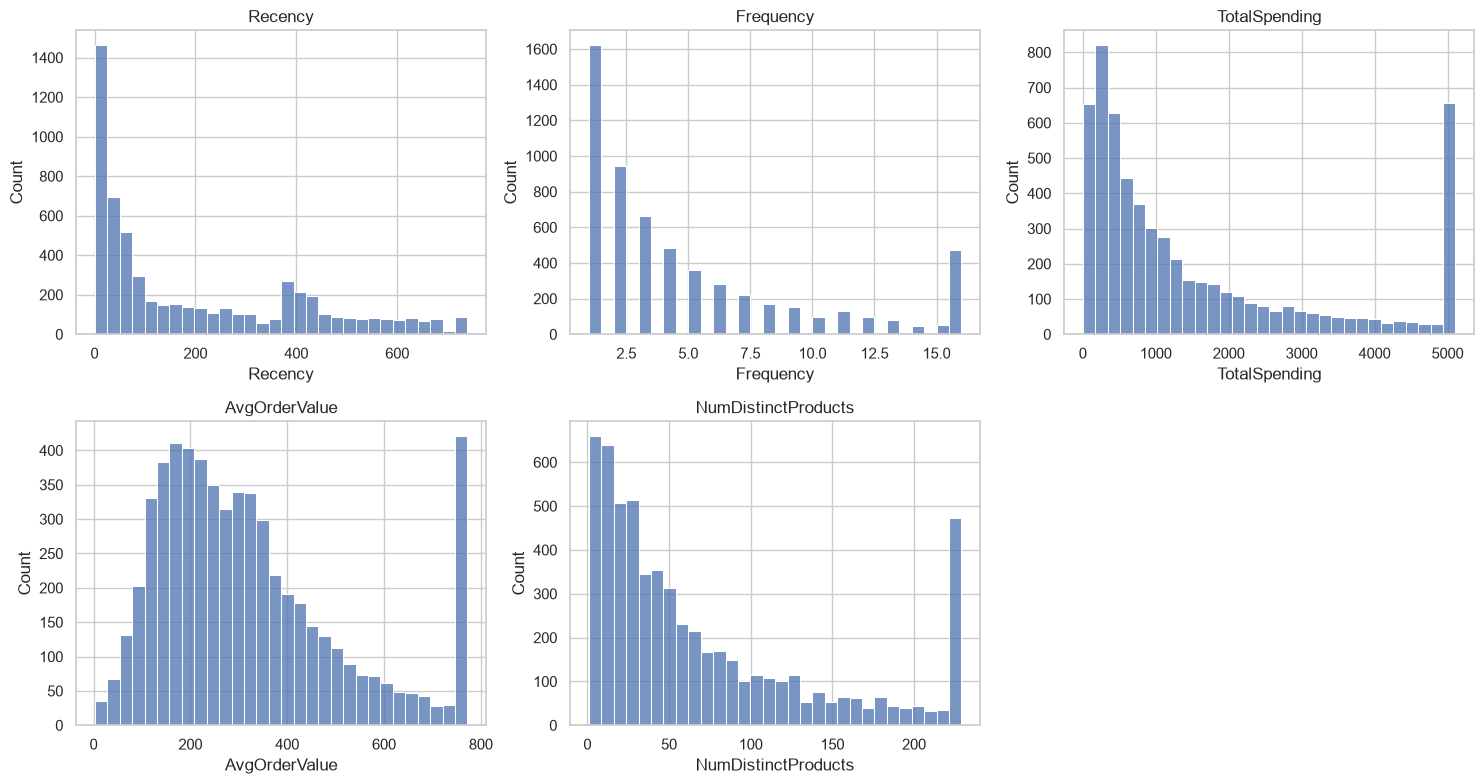

In [ ]:
# let's make a simple chart for each number, to see how it is spread out
columns_to_plot = ["Recency", "Frequency", "TotalSpending", "AvgOrderValue", "NumDistinctProducts"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()   # turn the grid of charts into a simple list

for i in range(len(columns_to_plot)):
    col_name = columns_to_plot[i]
    sns.histplot(df[col_name], bins=30, ax=axes[i])
    axes[i].set_title(col_name)

axes[5].axis("off")   # we only have 5 charts, hide the empty 6th box
plt.tight_layout()
plt.show()

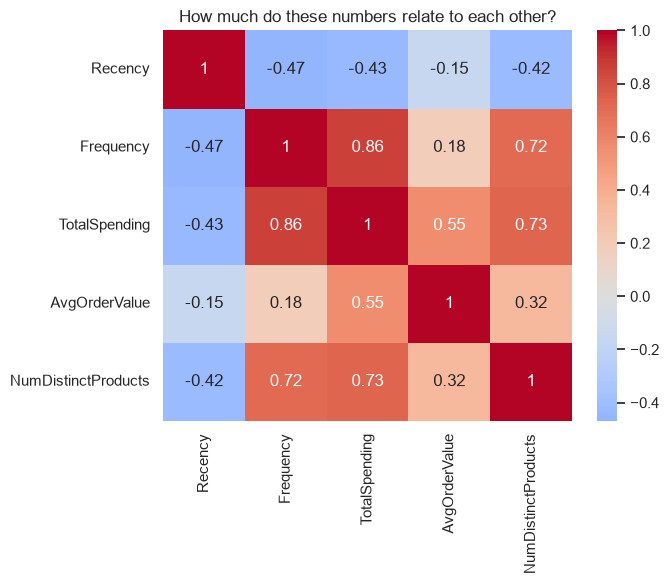

In [ ]:
# check if any two numbers move together (correlation)
columns_to_check = ["Recency", "Frequency", "TotalSpending", "AvgOrderValue", "NumDistinctProducts"]
correlation_table = df[columns_to_check].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(correlation_table, annot=True, cmap="coolwarm", center=0)
plt.title("How much do these numbers relate to each other?")
plt.tight_layout()
plt.show()

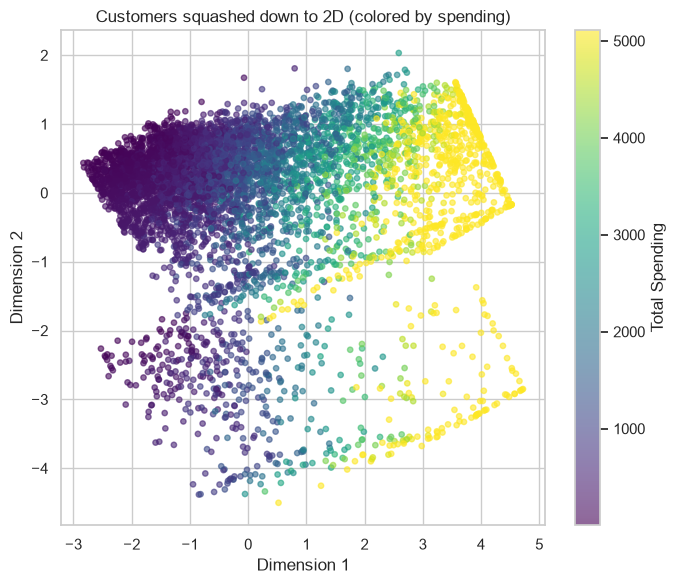

We kept about 70.3 % of the original information.


In [ ]:
# we have 6 numbers per customer - too many to draw on a normal chart
# PCA squashes them down to just 2 numbers, so we CAN draw them

pca_tool = PCA(n_components=2, random_state=42)
pcs = pca_tool.fit_transform(X_scaled.values)   # pcs = the 2 squashed numbers per customer

plt.figure(figsize=(7, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], c=df["TotalSpending"], cmap="viridis", s=15, alpha=0.6)
plt.colorbar(label="Total Spending")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Customers squashed down to 2D (colored by spending)")
plt.tight_layout()
plt.show()

# how much information did we keep after squashing?
info_kept = pca_tool.explained_variance_ratio_.sum() * 100
print("We kept about", round(info_kept, 1), "% of the original information.")

## Step 4: Customer Segmentation
Compares K-Means, Agglomerative Clustering, Gaussian Mixture Model, and DBSCAN.
Uses the Elbow Method, Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score to pick K.

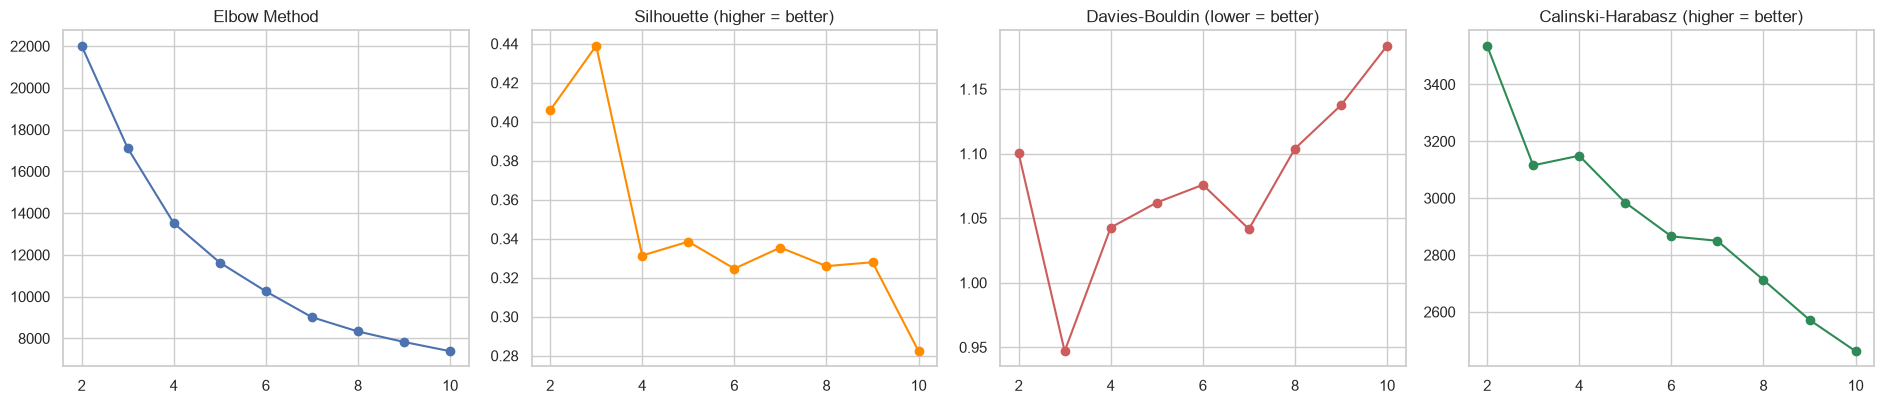

We will use K = 5


In [ ]:
# Xv = our scaled numbers, but as a plain numpy array (sklearn needs this format)
Xv = X_scaled.values

# we will try K = 2, 3, 4, ... up to 10, and see which one scores best
k_values_to_try = range(2, 11)

# empty lists to store the score for each K
inertia_scores = []
silhouette_scores = []
db_scores = []
ch_scores = []

for k in k_values_to_try:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(Xv)

    inertia_scores.append(model.inertia_)
    silhouette_scores.append(silhouette_score(Xv, model.labels_))
    db_scores.append(davies_bouldin_score(Xv, model.labels_))
    ch_scores.append(calinski_harabasz_score(Xv, model.labels_))

# draw all 4 scores side by side so we can compare
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
axes[0].plot(list(k_values_to_try), inertia_scores, "o-")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_values_to_try), silhouette_scores, "o-", color="darkorange")
axes[1].set_title("Silhouette (higher = better)")

axes[2].plot(list(k_values_to_try), db_scores, "o-", color="indianred")
axes[2].set_title("Davies-Bouldin (lower = better)")

axes[3].plot(list(k_values_to_try), ch_scores, "o-", color="seagreen")
axes[3].set_title("Calinski-Harabasz (higher = better)")

plt.tight_layout()
plt.show()

# we choose K=5 ourselves (good balance for business use)
OPTIMAL_K = 5
print("We will use K =", OPTIMAL_K)

In [ ]:
# now let's try 4 different ways to group the customers, and compare them

# Method 1: K-Means
kmeans_model = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(Xv)

# Method 2: Agglomerative (merges customers step by step)
agg_model = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage="ward")
agg_labels = agg_model.fit_predict(Xv)

# Method 3: Gaussian Mixture Model (gives a % chance per group)
gmm_model = GaussianMixture(n_components=OPTIMAL_K, random_state=42, n_init=5)
gmm_labels = gmm_model.fit_predict(Xv)

# Method 4: DBSCAN (groups by "how packed together" customers are)
neighbor_finder = NearestNeighbors(n_neighbors=5).fit(Xv)
distances, _ = neighbor_finder.kneighbors(Xv)
eps_value = np.percentile(np.sort(distances[:, -1]), 90)
dbscan_model = DBSCAN(eps=eps_value, min_samples=5)
dbscan_labels = dbscan_model.fit_predict(Xv)

# a simple function to score any grouping result
def score_this_grouping(labels, data):
    labels = np.array(labels)
    valid_points = labels != -1   # ignore "noise" points from DBSCAN
    if len(set(labels[valid_points])) < 2:
        return None, None, None
    sil = silhouette_score(data[valid_points], labels[valid_points])
    db = davies_bouldin_score(data[valid_points], labels[valid_points])
    ch = calinski_harabasz_score(data[valid_points], labels[valid_points])
    return sil, db, ch

# put all 4 results together
model_labels = {
    "KMeans": kmeans_labels,
    "Agglomerative": agg_labels,
    "GaussianMixture": gmm_labels,
    "DBSCAN": dbscan_labels,
}

# score each one and print a comparison table
results_table = []
for name in model_labels:
    labels = model_labels[name]
    sil, db, ch = score_this_grouping(labels, Xv)
    num_groups = len(set(labels)) - (1 if -1 in labels else 0)
    results_table.append({
        "Method": name,
        "Groups found": num_groups,
        "Silhouette": round(sil, 4),
        "DaviesBouldin": round(db, 4),
        "CalinskiHarabasz": round(ch, 1),
    })

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

# pick the best method (highest silhouette score, ignoring DBSCAN)
comparable_results = results_df[results_df["Method"] != "DBSCAN"]
best_row = comparable_results.sort_values("Silhouette", ascending=False).iloc[0]
BEST_MODEL = best_row["Method"]
primary_labels = model_labels[BEST_MODEL]

print("")
print("Best method:", BEST_MODEL)

         Method  Groups found  Silhouette  DaviesBouldin  CalinskiHarabasz
         KMeans             5      0.3385         1.0621            2984.4
  Agglomerative             5      0.2760         1.2156            2616.3
GaussianMixture             5      0.0907         2.2267            1536.0
         DBSCAN            15     -0.0235         0.8367              98.1

Best method: KMeans


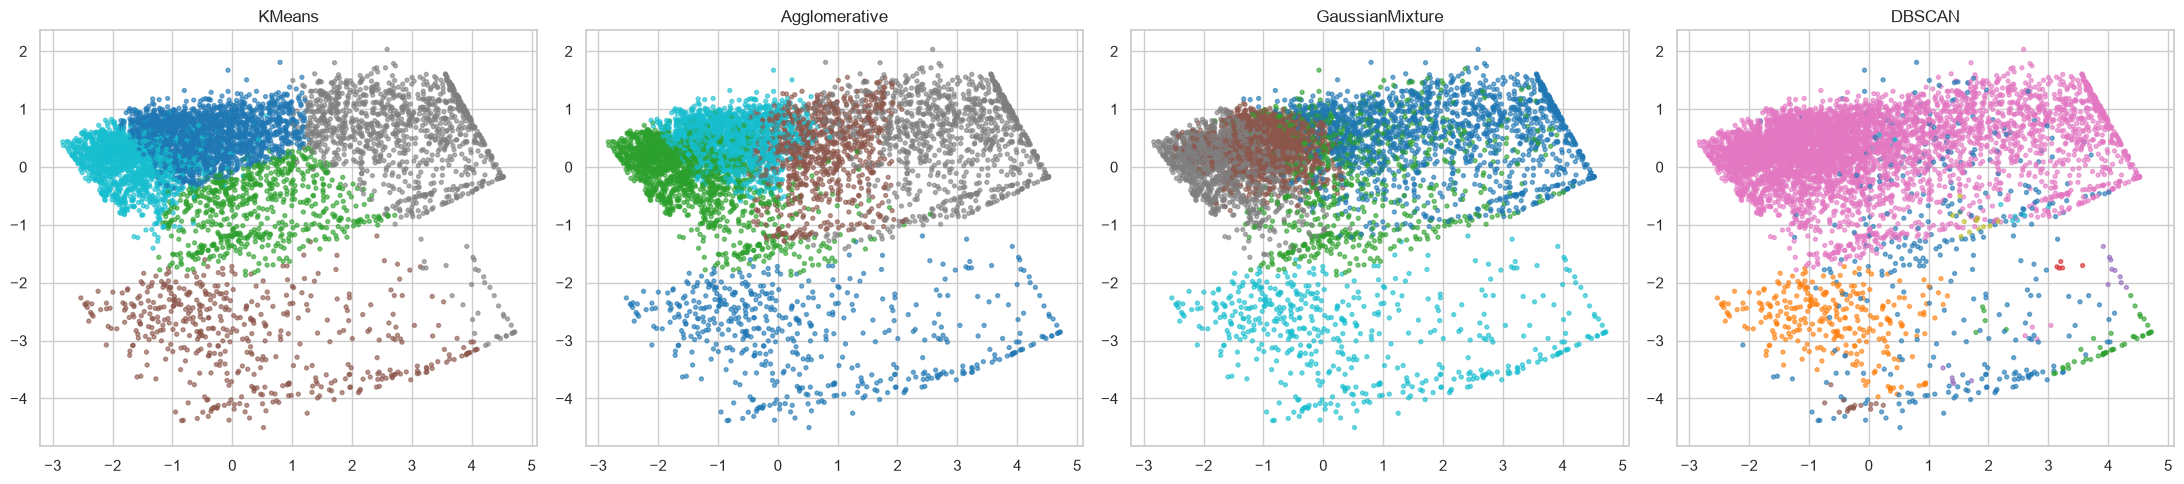

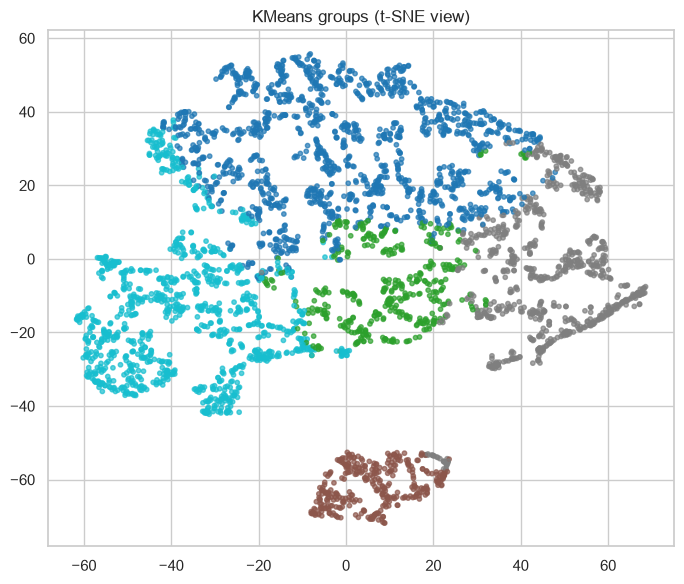

In [ ]:
# t-SNE is another way to squash data down to 2D, good for seeing tight groups
# it is slow, so if we have LOTS of customers, we just use a sample of 4000

if len(Xv) <= 4000:
    sample_rows = np.arange(len(Xv))
else:
    sample_rows = np.random.RandomState(42).choice(len(Xv), 4000, replace=False)

tsne_tool = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_result = tsne_tool.fit_transform(Xv[sample_rows])

# show all 4 methods side by side (using the PCA positions from before)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
method_names = list(model_labels.keys())

for i in range(len(method_names)):
    name = method_names[i]
    labels = model_labels[name]
    axes[i].scatter(pcs[:, 0], pcs[:, 1], c=labels, cmap="tab10", s=8, alpha=0.6)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

# now show just the best method, using t-SNE positions
best_labels_sample = np.array(primary_labels)[sample_rows]
plt.figure(figsize=(7, 6))
plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c=best_labels_sample, cmap="tab10", s=10, alpha=0.7)
plt.title(BEST_MODEL + " groups (t-SNE view)")
plt.tight_layout()
plt.show()

# save the group number for each customer into our main table
df["Cluster"] = primary_labels

## Step 5: Automated Cluster Profiling

In [ ]:
# let's give each group a real name, based on its numbers

feat5 = ["Recency", "Frequency", "TotalSpending", "AvgOrderValue", "NumDistinctProducts"]

# average value of each number, per group
profile = df.groupby("Cluster")[feat5].mean().round(1)
profile["Count"] = df.groupby("Cluster").size()

# z-score = how far above or below normal is this group's average?
overall_average = df[feat5].mean()
overall_spread = df[feat5].std()
z = (profile[feat5] - overall_average) / overall_spread

# simple rules: check the numbers, decide a name
def pick_a_name(row):
    if row["Recency"] > 0.8 and row["Frequency"] < -0.3:
        return "Dormant / At-Risk Customers"
    if row["TotalSpending"] > 0.8 and row["Frequency"] > 0.8:
        return "Premium / High-Value Customers"
    if row["Frequency"] > 0.3 and row["NumDistinctProducts"] > 0.3:
        return "Frequent / Loyal Buyers"
    if row["AvgOrderValue"] > 0.5 and row["Frequency"] < 0:
        return "High Average-Order, Low-Frequency Customers"
    if row["TotalSpending"] < -0.3 and row["Frequency"] < -0.3:
        return "Budget / Occasional Customers"
    return "Moderate / Average Customers"

# give every group a name (avoid using the same name twice)
group_names = {}
already_used_names = set()

for group_id in z.index:
    row = z.loc[group_id]
    name = pick_a_name(row)
    if name in already_used_names:
        name = name + " (Segment " + str(group_id) + ")"
    already_used_names.add(name)
    group_names[group_id] = name

profile["SegmentLabel"] = profile.index.map(group_names)
df["SegmentLabel"] = df["Cluster"].map(group_names)

print(profile[["SegmentLabel", "Count"] + feat5].to_string())

                                                    SegmentLabel  Count  Recency  Frequency  TotalSpending  AvgOrderValue  NumDistinctProducts
Cluster                                                                                                                                       
0                                   Moderate / Average Customers   2085     83.6        3.7          844.9          231.0                 51.0
1                    High Average-Order, Low-Frequency Customers    659    198.5        3.3         2047.9          604.6                 69.8
2        High Average-Order, Low-Frequency Customers (Segment 2)    492    196.5        3.7         1820.7          450.6                 62.7
3                                 Premium / High-Value Customers   1108     46.3       12.8         4185.2          404.6                172.4
4                                    Dormant / At-Risk Customers   1534    476.1        1.8          403.4          220.5                 27.0

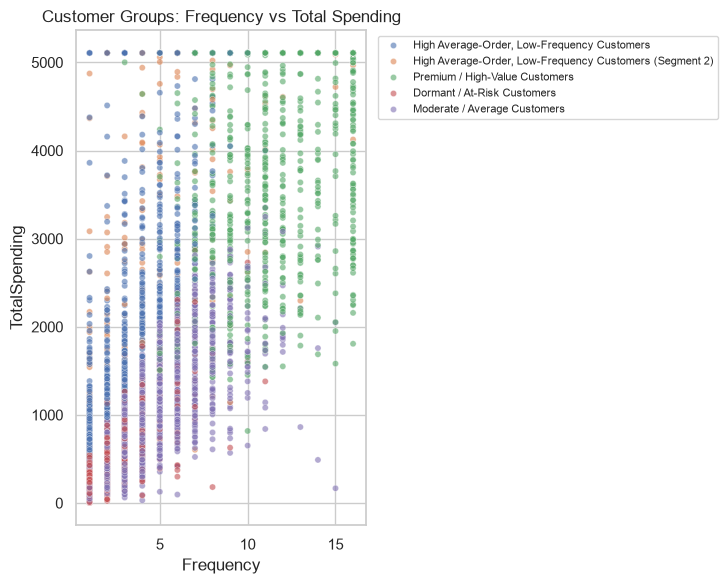

In [ ]:
# let's see the groups on a chart: how often they buy vs how much they spend
plt.figure(figsize=(7.5, 6))
sns.scatterplot(data=df, x="Frequency", y="TotalSpending", hue="SegmentLabel", s=20, alpha=0.6)
plt.title("Customer Groups: Frequency vs Total Spending")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## Step 6: Intelligent Similarity Search
Retrieve the Top-K most similar customers to a given CustomerID via cosine similarity, Euclidean distance, or a k-Nearest-Neighbors index.

In [ ]:
# find customers who are "similar" to a chosen customer

# get just the scaled number columns (the ones ending in _z)
z_columns = [c for c in df.columns if c.endswith("_z")]
Xz = df[z_columns].values

all_customer_ids = df["CustomerID"].values
id_to_row_number = {}
for i in range(len(all_customer_ids)):
    id_to_row_number[all_customer_ids[i]] = i

# calculate similarity/distance between every pair of customers (only once)
cosine_scores_table = cosine_similarity(Xz)
euclidean_distance_table = euclidean_distances(Xz)
nn_search_tool = NearestNeighbors(n_neighbors=min(50, len(df)), metric="cosine").fit(Xz)


def find_similar_customers(customer_id, how_many=5, method="cosine", same_group_only=False):
    row_number = id_to_row_number[customer_id]

    # decide who we're even allowed to compare against
    if same_group_only:
        this_group = df.iloc[row_number]["Cluster"]
        allowed = (df["Cluster"] == this_group).values.copy()
    else:
        allowed = np.ones(len(df), dtype=bool)
    allowed[row_number] = False   # never match a customer with themself

    if method == "cosine":
        scores = cosine_scores_table[row_number].copy()
        scores[~allowed] = -np.inf
        top_rows = np.argsort(scores)[::-1][:how_many]
        result = df.iloc[top_rows].copy()
        result["Score"] = scores[top_rows].round(4)
        score_column_name = "Similarity"

    elif method == "euclidean":
        distances = euclidean_distance_table[row_number].copy()
        distances[~allowed] = np.inf
        top_rows = np.argsort(distances)[:how_many]
        result = df.iloc[top_rows].copy()
        result["Score"] = distances[top_rows].round(4)
        score_column_name = "Distance"

    else:   # method == "knn"
        n_to_check = min(len(df), how_many * 10 + 10)
        distances, neighbor_rows = nn_search_tool.kneighbors(Xz[row_number].reshape(1, -1), n_neighbors=n_to_check)
        distances, neighbor_rows = distances[0], neighbor_rows[0]
        keep = allowed[neighbor_rows]
        neighbor_rows = neighbor_rows[keep][:how_many]
        distances = distances[keep][:how_many]
        result = df.iloc[neighbor_rows].copy()
        result["Score"] = (1 - distances).round(4)
        score_column_name = "Similarity"

    result = result.rename(columns={"Score": score_column_name})
    columns_to_show = ["CustomerID", "Country", "Recency", "Frequency", "TotalSpending", "SegmentLabel", score_column_name]
    return result[columns_to_show].reset_index(drop=True)


# --- try it out ---
demo_id = int(df["CustomerID"].iloc[10])   # change this to any real CustomerID you like
print("Looking at customer:", demo_id)
display(df[df["CustomerID"] == demo_id][["CustomerID", "Country", "Recency", "Frequency", "TotalSpending", "SegmentLabel"]])

print("")
print("Top 5 similar customers (cosine method):")
display(find_similar_customers(demo_id, how_many=5, method="cosine"))

print("")
print("Top 5 similar customers (same group only):")
display(find_similar_customers(demo_id, how_many=5, method="cosine", same_group_only=True))

Looking at customer: 12356


,CustomerID,Country,Recency,Frequency,TotalSpending,SegmentLabel
10,12356,Portugal,23,6,5107.3425,"High Average-Order, Low-Frequency Customers (S..."



Top 5 similar customers (cosine method):


,CustomerID,Country,Recency,Frequency,TotalSpending,SegmentLabel,Similarity
0,12432,Norway,43,5,5059.3200,"High Average-Order, Low-Frequency Customers (S...",0.9986
1,12406,Denmark,22,5,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9984
2,12449,Belgium,22,6,4835.8900,"High Average-Order, Low-Frequency Customers (S...",0.9972
3,12435,Denmark,80,6,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9970
4,12753,Japan,23,6,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9962



Top 5 similar customers (same group only):


,CustomerID,Country,Recency,Frequency,TotalSpending,SegmentLabel,Similarity
0,12432,Norway,43,5,5059.3200,"High Average-Order, Low-Frequency Customers (S...",0.9986
1,12406,Denmark,22,5,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9984
2,12449,Belgium,22,6,4835.8900,"High Average-Order, Low-Frequency Customers (S...",0.9972
3,12435,Denmark,80,6,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9970
4,12753,Japan,23,6,5107.3425,"High Average-Order, Low-Frequency Customers (S...",0.9962


## Step 7: Business Recommendation Engine

In [ ]:
# for each group, suggest some marketing actions

def get_recommendations(group_name, group_zscores):
    if "Premium" in group_name or "High-Value" in group_name:
        actions = ["Give them VIP treatment + bulk discounts",
                   "Give early access to new products",
                   "Offer priority shipping"]
    elif "Dormant" in group_name or "At-Risk" in group_name:
        actions = ["Send a win-back email with a discount",
                   "Ask them why they stopped buying",
                   "Show them new arrivals"]
    elif "Frequent" in group_name or "Loyal" in group_name:
        actions = ["Start a loyalty rewards program",
                   "Offer a subscription/auto-reorder option",
                   "Give referral rewards"]
    elif "High Average-Order" in group_name:
        actions = ["Send personalized reminders to reorder",
                   "Offer bundle deals"]
    elif "Budget" in group_name:
        actions = ["Offer low-cost starter deals",
                   "Offer free shipping over a certain amount"]
    else:
        actions = ["Send normal seasonal promotions"]

    # pick this group's 2 most unusual numbers, to explain WHY we suggest this
    top_2_reasons = group_zscores.abs().sort_values(ascending=False).index[:2]
    reason_parts = []
    for feature_name in top_2_reasons:
        if group_zscores[feature_name] > 0:
            reason_parts.append("above-average " + feature_name)
        else:
            reason_parts.append("below-average " + feature_name)
    reason = "Because this group has " + " and ".join(reason_parts)

    return actions, reason


# print suggestions for every group
for group_id in profile.index:
    group_name = profile.loc[group_id, "SegmentLabel"]
    group_size = int(profile.loc[group_id, "Count"])
    actions, reason = get_recommendations(group_name, z.loc[group_id])

    print("Group:", group_name, "(" + str(group_size), "customers)")
    print("  Reason:", reason)
    for action in actions:
        print("   -", action)
    print("")

Group: Moderate / Average Customers (2085 customers)
  Reason: Because this group has below-average Recency and below-average AvgOrderValue
   - Send normal seasonal promotions

Group: High Average-Order, Low-Frequency Customers (659 customers)
  Reason: Because this group has above-average AvgOrderValue and below-average Frequency
   - Send personalized reminders to reorder
   - Offer bundle deals

Group: High Average-Order, Low-Frequency Customers (Segment 2) (492 customers)
  Reason: Because this group has above-average AvgOrderValue and below-average Frequency
   - Send personalized reminders to reorder
   - Offer bundle deals

Group: Premium / High-Value Customers (1108 customers)
  Reason: Because this group has above-average Frequency and above-average TotalSpending
   - Give them VIP treatment + bulk discounts
   - Give early access to new products
   - Offer priority shipping

Group: Dormant / At-Risk Customers (1534 customers)
  Reason: Because this group has above-average Re

## Step 8: Explainable Insights

This simple tree matches our real grouping 91.6 % of the time.


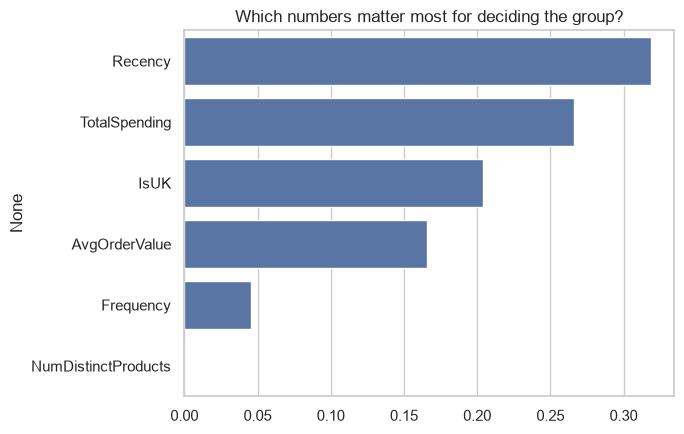

Recency                0.319
TotalSpending          0.266
IsUK                   0.204
AvgOrderValue          0.166
Frequency              0.046
NumDistinctProducts    0.000
dtype: float64


In [ ]:
# build a SIMPLE model that tries to copy our real grouping result
# if it can copy it well, its simple rules explain the grouping for us

all_features = ["Recency", "Frequency", "TotalSpending", "AvgOrderValue", "NumDistinctProducts", "IsUK"]

simple_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
simple_tree.fit(df[all_features], df["Cluster"])

# how well does the simple tree copy the real groups?
match_score = simple_tree.score(df[all_features], df["Cluster"])
print("This simple tree matches our real grouping", round(match_score * 100, 1), "% of the time.")

# which numbers mattered most to the tree?
importance_scores = pd.Series(simple_tree.feature_importances_, index=all_features)
importance_scores = importance_scores.sort_values(ascending=False)

plt.figure(figsize=(7, 4.5))
sns.barplot(x=importance_scores.values, y=importance_scores.index)
plt.title("Which numbers matter most for deciding the group?")
plt.tight_layout()
plt.show()

print(importance_scores.round(3))

In [ ]:
# write a simple sentence explaining what makes each group special

group_id_to_name = df.drop_duplicates("Cluster").set_index("Cluster")["SegmentLabel"].to_dict()

for group_id in z.index:
    row = z.loc[group_id]
    # find the top 3 most unusual numbers for this group
    top_3 = row.abs().sort_values(ascending=False).index[:3]

    explanation_parts = []
    for feature_name in top_3:
        if row[feature_name] > 0:
            explanation_parts.append(feature_name + " is higher than average")
        else:
            explanation_parts.append(feature_name + " is lower than average")

    group_name = group_id_to_name[group_id]
    print("-", group_name, ":", "; ".join(explanation_parts))

- Moderate / Average Customers : Recency is lower than average; AvgOrderValue is lower than average; TotalSpending is lower than average
- High Average-Order, Low-Frequency Customers : AvgOrderValue is higher than average; Frequency is lower than average; TotalSpending is higher than average
- High Average-Order, Low-Frequency Customers (Segment 2) : AvgOrderValue is higher than average; Frequency is lower than average; TotalSpending is higher than average
- Premium / High-Value Customers : Frequency is higher than average; TotalSpending is higher than average; NumDistinctProducts is higher than average
- Dormant / At-Risk Customers : Recency is higher than average; TotalSpending is lower than average; Frequency is lower than average


## Done!
You now have: cleaned real transaction data, engineered RFM+ features, 4 clustering models compared, automated segment profiles and labels, a similarity search function, business recommendations per segment, and explainability.

To export any table, run e.g. `df.to_csv("segmented_customers.csv", index=False)` then `files.download("segmented_customers.csv")`.